In [1]:
import pandas as pd
import numpy as np
import math
import seaborn as sns
import time
import requests
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import itertools
import gsd.hoomd
import hoomd
from scipy.spatial.distance import pdist
import matplotlib.pyplot as plt

In [2]:
testFiltered = pd.DataFrame({'Abundance':[44],'Beads':[20],'Diameter':[1]})
sigma = 1.0 # reduced
mass = 1.0  # reduced
epsilon = 1.0 # reduced
kT = 1.5 # reduced
#dt = 0.0001 # reduced
dt = 0.001
domainSize = sigma*1
ABsize=sigma*4
num_B = 0


total_beads = 0
bead0 = list()
bead0.append(0)
typeidsList = list() #############NEW########################
dias = list()
for i in range(len(testFiltered)):
    total_beads=total_beads+testFiltered.loc[i]['Abundance']*testFiltered.loc[i]['Beads']
    typeidsList.append([str(i)]*int(testFiltered.loc[i]['Abundance'])*testFiltered.loc[i]['Beads'])
    dias.append([testFiltered.loc[i]['Diameter']]*int(testFiltered.loc[i]['Abundance'])*testFiltered.loc[i]['Beads'])
    bead0.append(total_beads)
total_beads = int(total_beads)
typeidsList.append([str(len(testFiltered))] * num_B)
typeidsList = list(itertools.chain.from_iterable(typeidsList))

cpu = hoomd.device.CPU()
#sim = hoomd.Simulation(device=cpu, seed=2)

In [3]:
def layoutSimulation(numBonds, beads_per_chain, bead_diameter, graft_spacing_ratio,tip_gap_ratio,graft_sites_rod0,graft_sites_rod1):
    cpu = hoomd.device.CPU()
    testFiltered = pd.DataFrame({'Abundance':[numBonds],'Beads':[beads_per_chain],'Diameter':[bead_diameter]})


    n_chains = sum(testFiltered['Abundance'])
    Lx=30 # 1 micron
    Ly=28 # 1 micron
    domainSize = bead_diameter
    
    #Lz=beads_per_chain*domainSize+2*ABsize
    #Lz = int(max(testFiltered['Height'])) + 50
    Lz = 28
    z0 = -Lz/2+(0.5*sigma)
    rod_beads = 22                 # NEW: fixed 22-bead rods
    rod_spacing = graft_spacing_ratio * domainSize  # you can still use this as x-spacing along rod
    rod0_bead_indices = []         # NEW: to store bead indices for rod0
    rod1_bead_indices = []         # NEW: to store bead indices for rod1
    bead_spacing = domainSize
    
    positions = []        # list of [x, y, z]
    bonds = []            # list of [i, j] index pairs
    bondTypes = []        # type name string per bond
    Bead_diameters = []   # diameter per bead (same length as positions)
    Bead_Bonds = []       # parallel to bonds, stores bond type name
    bead0 = []            # OPTIONAL: store first-bead index per chain (if you want)
    
    particles = 0         # global particle counter
    
    # --- geometry parameters for two "rods" made of chain first beads ---
    chains_per_rod = int(numBonds/2)       # first 22 chains = rod 0, next 22 = rod 1
    #graft_spacing = graft_spacing_ratio * domainSize


    rod_spacing = graft_spacing_ratio * domainSize
    rod_start_x = -0.5 * (rod_beads - 1) * rod_spacing

    # z positions of the two “rods”
    beads_per_chain = testFiltered.loc[0]['Beads']-1
    #chain_length = (beads_per_chain - 1) * bead_spacing
    chain_length = (beads_per_chain) * bead_spacing
    tip_gap = tip_gap_ratio * sigma   # initial gap between top of lower chains and bottom of upper chains
    z_sep = 2.0 * chain_length + tip_gap
    z_rod0 = -0.5 * z_sep
    z_rod1 = +0.5 * z_sep
    
    chain_first_bead_idx = []   # global index of bead0 for each chain, in creation order
    global_chain_index = 0

    for i in range(len(testFiltered)):
        numChains = int(testFiltered.loc[i, 'Abundance'])
        diameter = testFiltered.loc[i, 'Diameter']
        beads_per_chain = testFiltered.loc[i]['Beads']

        
    for i in range(rod_beads):
        x = rod_start_x + i * rod_spacing
        y = 0.0
        z = z_rod0
        positions.append([x, y, z])
        Bead_diameters.append(bead_diameter)  # or separate rod diameter
        rod0_bead_indices.append(particles)
    
        if i > 0:
            bonds.append([particles - 1, particles])
            bondTypes.append('rod')
            Bead_Bonds.append('rod')
    
        particles += 1
    
    # ---------------------
    # Build rod 1 (upper)
    # ---------------------
    for i in range(rod_beads):
        x = rod_start_x + i * rod_spacing
        y = 0.0
        z = z_rod1
        positions.append([x, y, z])
        Bead_diameters.append(bead_diameter)
        rod1_bead_indices.append(particles)
    
        if i > 0:
            bonds.append([particles - 1, particles])
            bondTypes.append('rod')
            Bead_Bonds.append('rod')
    
        particles += 1




    chain_first_bead_idx = []     # first bead of each *grafted* chain
    lower_chain_ends = []         # terminal bead indices for rod0 chains
    upper_chain_ends = []         # terminal bead indices for rod1 chains
    
    # --- chains on rod 0 ---
    for site in graft_sites_rod0:
        anchor_idx = rod0_bead_indices[site]       # which bead on rod0
        anchor_pos = np.array(positions[anchor_idx])
    
        # first graft bead sits exactly at rod bead position
        first_bead_index = particles
        chain_first_bead_idx.append(first_bead_index)
        bead0.append(first_bead_index)
    
        for b in range(beads_per_chain):
            if b == 0:
                pos = anchor_pos+ np.array([0.0, 0.0, (1) * bead_spacing])
                #pos = anchor_pos+ np.array([0.0, 0.0, -(1) * bead_spacing])
            else:
                # grow up (+z) from rod 0
                pos = anchor_pos + np.array([0.0, 0.0, (b+1) * bead_spacing])
                #pos = anchor_pos + np.array([0.0, 0.0, -(b+1) * bead_spacing])
    
            positions.append(pos.tolist())
            Bead_diameters.append(bead_diameter)
            if b == 0:
                bonds.append([anchor_idx, particles])
                bondTypes.append('chain')
                Bead_Bonds.append('chain')
            if b > 0:
                bonds.append([particles - 1, particles])
                bondTypes.append('chain')
                Bead_Bonds.append('chain')
    
            particles += 1
    
        # last bead in this chain:
        chain_end_idx = particles - 1
        lower_chain_ends.append(chain_end_idx)
    
    # --- chains on rod 1 ---
    for site in graft_sites_rod1:
        anchor_idx = rod1_bead_indices[site]
        anchor_pos = np.array(positions[anchor_idx])
    
        first_bead_index = particles
        chain_first_bead_idx.append(first_bead_index)
        bead0.append(first_bead_index)
    
        for b in range(beads_per_chain):
            if b == 0:
                pos = anchor_pos+ np.array([0.0, 0.0, -(1) * bead_spacing])
                #pos = anchor_pos+ np.array([0.0, 0.0, (1) * bead_spacing])
            else:
                # grow down (-z) from rod 1
                pos = anchor_pos + np.array([0.0, 0.0, -(b+1) * bead_spacing])
                #pos = anchor_pos + np.array([0.0, 0.0, (b+1) * bead_spacing])
    
            positions.append(pos.tolist())
            Bead_diameters.append(bead_diameter)
            if b == 0:
                bonds.append([anchor_idx, particles])
                bondTypes.append('chain')
                Bead_Bonds.append('chain')
            if b > 0:
                bonds.append([particles - 1, particles])
                bondTypes.append('chain')
                Bead_Bonds.append('chain')
    
            particles += 1


        chain_end_idx = particles - 1
        upper_chain_ends.append(chain_end_idx)
        # Record the index of bead 0 for this chain

    n_bridges = min(len(lower_chain_ends), len(upper_chain_ends))
    
    for i in range(n_bridges):
        i_lower = lower_chain_ends[i]
        i_upper = upper_chain_ends[i]
        bonds.append([i_lower, i_upper])
        if(i==0):
            bondTypes.append('Bridge')
            Bead_Bonds.append('Bridge')
        else:
            bondTypes.append('Bridge1')
            Bead_Bonds.append('Bridge1')



    angle_groups = []
    angle_typeids = []
    angle_type_to_id = {'rod_bend': 0, 'chain_bend': 1,'graft_bend':2}


    anchor_tags = []
    chain1_tags = []
    signs = []

    half = numBonds // 2  # integer

    for chain_idx, first in enumerate(chain_first_bead_idx):
        if chain_idx < half:
            # This chain is on rod 0
            site = graft_sites_rod0[chain_idx]          # which rod bead
            anchor_idx = rod0_bead_indices[site]
        else:
            # This chain is on rod 1
            j = chain_idx - half                        # index within rod1 chain list
            site = graft_sites_rod1[j]
            anchor_idx = rod1_bead_indices[site]
    
        chain_start = first
        chain_end = first + beads_per_chain


    
        # Graft angle: rod bead – first chain bead – second chain bead
        angle_groups.append([anchor_idx, chain_start, chain_start + 1])
        angle_typeids.append(angle_type_to_id['chain_bend'])  # or 'graft_bend' if you add that
    
        # Internal chain angles
        for b in range(chain_start + 1, chain_end - 1):
            i = b - 1
            j = b
            k = b + 1
            angle_groups.append([i, j, k])
            angle_typeids.append(angle_type_to_id['chain_bend'])



    # --- rod 0 bending ---
    for idx in range(len(rod0_bead_indices) - 2):
        i = rod0_bead_indices[idx]
        j = rod0_bead_indices[idx + 1]
        k = rod0_bead_indices[idx + 2]
        angle_groups.append([i, j, k])
        angle_typeids.append(angle_type_to_id['rod_bend'])
    
    # --- rod 1 bending ---
    for idx in range(len(rod1_bead_indices) - 2):
        i = rod1_bead_indices[idx]
        j = rod1_bead_indices[idx + 1]
        k = rod1_bead_indices[idx + 2]
        angle_groups.append([i, j, k])
        angle_typeids.append(angle_type_to_id['rod_bend'])




    def pick_rod_neighbor(rod_bead_indices, site):
        """Choose a neighbor rod bead to define the rod axis near the graft."""
        if site > 0:
            return rod_bead_indices[site - 1]
        elif site < len(rod_bead_indices) - 1:
            return rod_bead_indices[site + 1]
        else:
            return None  # degenerate case: rod only 1 bead; won't happen here
    
    half = len(graft_sites_rod0)   # number of chains on rod 0
    dihedral_groups = []     # list of [i, j, k, l]
    dihedral_typeids = []    # list of type ids for each dihedral
    
    dihedral_type_to_id = {'graft_torsion': 0}  # only one dihedral type for now
    for chain_idx, first in enumerate(chain_first_bead_idx):
        # Determine which rod and which graft site this chain belongs to
        if chain_idx < half:
            # Chain on rod 0
            site = graft_sites_rod0[chain_idx]           # which rod bead index
            anchor_idx = rod0_bead_indices[site]         # anchor rod bead
            neighbor_idx = pick_rod_neighbor(rod0_bead_indices, site)
            #dihedral_typeids.append(dihedral_type_to_id['graft_torsion'])
            sign = 1.0
        else:
            # Chain on rod 1
            j = chain_idx - half
            site = graft_sites_rod1[j]
            anchor_idx = rod1_bead_indices[site]
            neighbor_idx = pick_rod_neighbor(rod1_bead_indices, site)
            #dihedral_typeids.append(dihedral_type_to_id['graft_down'])
            sign = -1.0

        anchor_tags.append(anchor_idx)
        chain1_tags.append(first)
        signs.append(sign)
        # Skip if we somehow don't have a neighbor (shouldn't happen with 22-bead rods)
        if neighbor_idx is None:
            continue
    
        first_chain_bead = first   # chain_start
    
        # Angle: (neighbor rod bead, anchor rod bead, first chain bead)
        # central bead = anchor rod bead → angle between rod segment and chain segment
        angle_groups.append([neighbor_idx, anchor_idx, first_chain_bead])
        angle_typeids.append(angle_type_to_id['graft_bend'])

        dihedral_groups.append([first_chain_bead, neighbor_idx, anchor_idx, first_chain_bead+1])
        #dihedral_groups.append([rod_bead_indices[site + 1], neighbor_idx, anchor_idx, first_chain_bead])
        dihedral_typeids.append(dihedral_type_to_id['graft_torsion'])

    
    snapshot = hoomd.Snapshot()
    snapshot.particles.N = len(positions)
    list_of_Types = [str(i) for i in range(len(testFiltered))] ###########NEW################
    snapshot.particles.types = ['0'] ##################NEW###############    
    #unique_typesParticles = [str(i) for i in range(len(testFiltered))]
    #snapshot.particles.types = [str(i) for i in unique_typesParticles]   # must come BEFORE typeid
    #type_mapParticles = {v: i for i, v in enumerate(unique_typesParticles)}

    #typeidsList = list() #############NEW########################
    #for i in range(len(testFiltered)):
    #    typeidsList.append([str(i)]*int(testFiltered.loc[i]['Abundance'])*testFiltered.loc[i]['Beads'])
    #typeidsList = list(itertools.chain.from_iterable(typeidsList))
    dihedral_groups  = np.asarray(dihedral_groups,  dtype=np.int32)
    dihedral_typeids = np.asarray(dihedral_typeids, dtype=np.int32)
    
    if snapshot.communicator.rank == 0:
        snapshot.dihedrals.N     = len(dihedral_groups)
        snapshot.dihedrals.types = ['graft_torsion']
        snapshot.dihedrals.group[:]   = dihedral_groups
        snapshot.dihedrals.typeid[:]  = dihedral_typeids


    snapshot.particles.typeid[:] = 0
    snapshot.bonds.N = len(bonds)
    unique_typesBonds = np.unique(bondTypes) 
    snapshot.bonds.types = [str(i) for i in unique_typesBonds]   # must come BEFORE typeid
    type_mapBonds = {v: i for i, v in enumerate(unique_typesBonds)}
    snapshot.bonds.typeid[:] = [type_mapBonds[a] for a in bondTypes]

    
    
    angle_groups   = np.asarray(angle_groups,   dtype=np.int32)
    angle_typeids  = np.asarray(angle_typeids,  dtype=np.int32)
    
    #snapshot = sim.state.get_snapshot()
    if snapshot.communicator.rank == 0:
        snapshot.angles.N = len(angle_groups)
        snapshot.angles.types = ['rod_bend', 'chain_bend','graft_bend']  # order must match angle_type_to_id
        snapshot.angles.group[:]   = angle_groups
        snapshot.angles.typeid[:]  = angle_typeids

    snapshot.bonds.group[:] = bonds
    new_box = hoomd.Box(Lx=Lx, Ly=Ly, Lz=Lz, xy=0, xz=0, yz=0)
    snapshot.configuration.box = new_box
    snapshot.particles.diameter[:] = Bead_diameters
    snapshot.particles.position[:] = positions
    df=pd.DataFrame({"Diameters":Bead_Bonds, 'Bonds':bondTypes})
    dfDrop=df.drop_duplicates(subset=['Diameters', 'Bonds'])
    my_dict = pd.Series(dfDrop['Diameters'].values, index=dfDrop['Bonds']).to_dict()

    #midBead1=rod1_bead_indices[len(rod1_bead_indices)/2]
    #midBead0=rod0_bead_indices[len(rod0_bead_indices)/2]
    assert all(0 <= s < rod_beads for s in graft_sites_rod0)
    assert all(0 <= s < rod_beads for s in graft_sites_rod1)
    assert numBonds == len(graft_sites_rod0) + len(graft_sites_rod1)
    return snapshot, [bonds,bondTypes],anchor_tags,chain1_tags,signs

In [4]:
def Equilibrate_MD(sim,forces,bridge_pairs):
    temp = list()
    kinetics = list()
    potent = list()
    log_interval = 5000

    lj,angle_force,fene,rod_bond,bridge_bond,angle,dihedral,custom=forces
    md_integrator = hoomd.md.Integrator(dt=dt*0.1)
    #md_integrator.forces = [lj,angle_force,fene,rod_bond,bridge_bond,angle,dihedral]
    md_integrator.forces = [lj,angle_force,fene,rod_bond,bridge_bond,angle,custom]
    md_integrator.methods = [hoomd.md.methods.Brownian(filter=hoomd.filter.All(),kT=0.05, default_gamma=20.0)]
    sim.operations.integrator = md_integrator
    thermo = hoomd.md.compute.ThermodynamicQuantities(filter=hoomd.filter.All())
    sim.operations.computes.append(thermo)
    gsd_writer = hoomd.write.GSD(
        filename="MorseTestEquil.gsd",   # output file
        trigger=hoomd.trigger.Periodic(1000),  # write every 1000 steps
        mode="wb",                   # "wb" = write new file, "ab" = append
        filter=hoomd.filter.All(),   # which particles to save
        dynamic=['property', 'momentum']  # what to save
    )
    sim.operations.writers.append(gsd_writer)
    bound = []
    i=0
    #for step in range(0, 10000000, log_interval):
    for step in range(0, 1000000, log_interval):
        sim.run(log_interval)
        temp.append(thermo.kinetic_temperature)
        kinetics.append(thermo.kinetic_energy)
        potent.append(thermo.potential_energy)
        n_bound, frac_bound, state = bridge_state(sim,bridge_pairs=bridge_pairs,r_bind = 1.4)
        bound.append(n_bound)
        i=i+1
        if(step > 500000):
            if(n_bound == 2):
                if(len(bound) >= 3 and bound[-2] == 2 and bound[-3] == 2):
                    break
    timesteps = range(0, len(potent))
    plt.plot(timesteps, potent, label='Potential Energy')
    plt.xlabel('Frame')
    plt.ylabel('Value')
    plt.legend()
    plt.show()

    plt.plot(timesteps, bound, label='N Bound')
    plt.xlabel('Frame')
    plt.ylabel('Value')
    plt.legend()
    plt.show()
    return sim

In [5]:
def TempSampling(state, temperatures,bridge_pairs,forces, assosciation = False):
    results = []
    snapshot = state
    for T in temperatures:
        print(f"\n=== Running at kT = {T} ===")
        sim = hoomd.Simulation(device=cpu, seed=1)
        sim.create_state_from_snapshot(snapshot) ##########SWITCH BACKKKKK############
        # Update Brownian method’s kT
        lj,angle_force,fene,rod_bond,bridge_bond,angle,dihedral,custom=forces
        forces1 = forces[:6] + forces[6+1:]
        md_integrator = hoomd.md.Integrator(dt=dt*0.1)
        md_integrator.forces = forces1
        
        md_integrator.methods = [hoomd.md.methods.Brownian(filter=hoomd.filter.All(),kT=T, default_gamma=20.0)]
        sim.operations.integrator = md_integrator
        thermo = hoomd.md.compute.ThermodynamicQuantities(filter=hoomd.filter.All())
        sim.operations.computes.append(thermo)
    
        # Equilibrate
        #sim.run(2500000)
    
        # Sample bridge state over time
        bound_counts = []
        bound_fracs = []
        states = []
        potent = []
        filename = f"FullCurveRigid_RigidChain{T}.gsd"
        gsd_writer = hoomd.write.GSD(
            filename=filename,   # output file
            trigger=hoomd.trigger.Periodic(10),  # write every 1000 steps
            mode="wb",                   # "wb" = write new file, "ab" = append
            filter=hoomd.filter.All(),   # which particles to save
            dynamic=['property', 'momentum']  # what to save
        )
        sim.operations.writers.append(gsd_writer)

        # Burn-in at this T before recording
        sim.run(50000)

        if(assosciation == True):
            n_samples = 500
            sample_interval = 1000
            for _ in range(n_samples):
                sim.run(sample_interval)
                n_bound, frac_bound, state = bridge_state(sim,bridge_pairs=bridge_pairs,r_bind = 1.4)
                bound_counts.append(n_bound)
                bound_fracs.append(frac_bound)
                states.append(state)
                potent.append(thermo.potential_energy)
                #if(n_bound == 2):
                #    print("Found in " + str(_))
                #    break
        else:
            n_samples = 10000
            sample_interval = 100
            for _ in range(n_samples):
                sim.run(sample_interval)
                n_bound, frac_bound, state = bridge_state(sim,bridge_pairs=bridge_pairs,r_bind = 1.4)
                bound_counts.append(n_bound)
                bound_fracs.append(frac_bound)
                states.append(state)
                potent.append(thermo.potential_energy)

        #gsd_writer = hoomd.write.GSD(
        #filename="Dimer_6beads.gsd",   # output file
        #trigger=hoomd.trigger.Periodic(1000),  # write every 1000 steps
        #mode="wb",                   # "wb" = write new file, "ab" = append
        #filter=hoomd.filter.All(),   # which particles to save
        #dynamic=['property', 'momentum']  # what to save
        #)
        #sim.operations.writers.append(gsd_writer)
        timesteps = range(0, len(potent))
        plt.plot(timesteps, potent, label='Temperature Potential Energy')
        #plt.plot(timesteps, bound_fracs, label='frac_bound')
        plt.show()
        plt.plot(timesteps, bound_fracs, label='frac_bound')
        plt.show()
        # Time averages at this T
        avg_n_bound = np.mean(bound_counts)
        avg_frac_bound = np.mean(bound_fracs)
        avg_state = np.mean(states)
        print(f"kT={T}: <n_bound>={avg_n_bound:.2f} / {len(bridge_pairs)}, "
              f"<frac_bound>={avg_frac_bound:.2f}, <state>={avg_state:.3f}")
        results.append([potent,bound_counts,[T]*len(potent)])
        #results.append((T, avg_n_bound, avg_frac_bound, avg_state))
        #del(sim)
    return results, sim

In [6]:
def bridge_state(sim, bridge_pairs, r_bind):
    n_bound, frac_bound = count_bound_bridges(sim, bridge_pairs, r_bind)
    # state 0 = fully bound, 1 = fully unbound
    #state = 1.0 - frac_bound
    state = 1.0 if n_bound == 0 else 0.0
    return n_bound, frac_bound, state

In [7]:
def count_bound_bridges(sim, bridge_pairs, r_bind):
    snap = sim.state.get_snapshot()
    if snap.communicator.rank != 0:
        return 0, 0.0  # only rank 0 does the counting

    pos = snap.particles.position
    dists = [
        np.linalg.norm(pos[i] - pos[j])
        for (i, j) in bridge_pairs
    ]

    n_bound = sum(d < r_bind for d in dists)
    frac_bound = n_bound / len(bridge_pairs) if bridge_pairs else 0.0
    return n_bound, frac_bound

In [8]:
def autocorrelation(x, max_lag=None):
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    n = len(x)
    if max_lag is None:
        max_lag = n // 10

    c0 = np.dot(x, x) / n
    acf = np.empty(max_lag)
    for lag in range(max_lag):
        acf[lag] = np.dot(x[:n-lag], x[lag:]) / (n - lag) / c0
    return acf

def integrated_autocorrelation_time(acf, dt=1.0):
    # stop when acf first becomes <= 0
    positive = np.where(acf > 0)[0]
    if len(positive) == 0:
        return 0.5 * dt
    last = positive[-1]
    tau_int = dt * (0.5 + np.sum(acf[1:last+1]))
    return tau_int

In [9]:
def getBondPairs(bonds, bondTypes):
    bridge_pairs = [
    (int(bonds[k][0]), int(bonds[k][1]))
    for k, btype in enumerate(bondTypes)
    if btype.lower() == 'bridge' or btype.lower() == 'bridge1'
    ]

    return bridge_pairs

In [10]:
def fireMinimization(sim, forces):
    lj,angle_force,fene,rod_bond,bridge_bond,angle,dihedral=forces
    fire = hoomd.md.minimize.FIRE(
        dt=dt*0.01,
        forces = [lj, angle_force,fene,rod_bond,angle,dihedral],
        energy_tol=1e-2,
        force_tol=1e-2,
        angmom_tol=0.0
    )
    fire.methods = [md.methods.ConstantVolume(filter = typeA_filter)]
    sim.operations.integrator = fire
    sim.run(50000)
    return sim

In [11]:
def relax_MD(sim,forces):
    lj,angle_force,fene,rod_bond,bridge_bond,angle,dihedral,custom=forces
    relax = hoomd.md.Integrator(dt=dt*0.1)
    #relax.forces = [lj, angle_force,fene,rod_bond,bridge_bond,angle,dihedral]
    relax.forces = [lj, angle_force,fene,rod_bond,angle, custom]
    relax.methods = [hoomd.md.methods.Brownian(filter=hoomd.filter.All(),kT=0.05, default_gamma=1000.0)]
    sim.operations.integrator = relax
    t0 = time.perf_counter()
    sim.run(100000)
    t1 = time.perf_counter()
    print("steps/sec:", 100000/(t1-t0))
    return sim

In [12]:
def forces_MD(morseParams,chainParams,rodParams,anchor_tags,chain1_tags,graft_spacing,signs,assosciation = False):

    #morseParams = [U_Morse, F_Morse,r_MorseMin,r_MorseMax]
    #chainParams = [chain_bend_Stiffness,chain_bond_stiffness]
    #rodParams = [rod_bend_Stiffness,rod_bond_Stiffness]

    z_align = GraftZAlignForce(
        anchor_tags=anchor_tags,
        chain1_tags=chain1_tags,
        signs=signs,
        k=100.0,   # tune this
        d=1.0      # desired offset in z
    )
    dihedral = hoomd.md.dihedral.Periodic()
    
    # Parameters:
    # k: stiffness (energy)
    # d, n: multiplicity and sign
    # phi0: equilibrium dihedral angle
    
    dihedral.params['graft_torsion'] = dict(
        k=0,   # choose something like 50–200 in your reduced units
        d=1,
        n=1,
        phi0=0.0        # target torsion angle (0 rad)
    )

    
    r_MorseMin = morseParams[2]
    r_MorseMax = morseParams[3]
    U_Morse = morseParams[0]
    F_Morse = morseParams[1]
    
    epsilon_B = 3*sigma*kT/sigma

    

    theta0 = np.pi                     # straight = 180°
    n = 1000
    theta_values = np.linspace(0, np.pi, n)
    
    # Chain bending stiffness
    epsilon_chain = chainParams[0] * kT           # you can tune this
    U_chain = epsilon_chain * (1 - np.cos(theta_values - theta0))
    F_chain = -epsilon_chain * np.sin(theta_values - theta0)
    
    # Rod bending stiffness (usually stiffer)
    epsilon_rod = rodParams[0] * kT            # make the rod more rigid
    U_rod = epsilon_rod * (1 - np.cos(theta_values - theta0))
    F_rod = -epsilon_rod * np.sin(theta_values - theta0)

    epsilon_graft = rodParams[0] * kT            # make the rod more rigid
    U_graft = 0 * (1 - np.cos(theta_values - theta0))
    F_graft = 0 * np.sin(theta_values - theta0)
    
    angle_force = hoomd.md.angle.Table(width=n)
    
    # Two angle types: one for rods, one for chains
    angle_force.types = ['rod_bend', 'chain_bend','graft_bend']
    
    angle_force.params['rod_bend'] = dict(
        U   = U_rod.tolist(),
        tau = F_rod.tolist()
    )
    
    angle_force.params['chain_bend'] = dict(
        U   = U_chain.tolist(),
        tau = F_chain.tolist()
    )

    angle_force.params['graft_bend'] = dict(
        U   = U_graft.tolist(),
        tau = F_graft.tolist()
    )

    angle = hoomd.md.angle.Harmonic()
    angle.params['graft_bend'] = dict(k=100, t0=np.pi/2) 
    angle.params['rod_bend'] = dict(k=0, t0=np.pi/2) 
    angle.params['chain_bend'] = dict(k=0, t0=np.pi/2) 
    
    nl = hoomd.md.nlist.Cell(buffer =0.4)
    lj = hoomd.md.pair.LJ(nlist=nl)
    epsilon = 1
    lj.params[('0', '0')] = dict(epsilon=epsilon*1, sigma=sigma)
    lj.r_cut[('0', '0')] = 2**(1/6) * sigma
    lj.r_on[('0', '0')] = 0.0
    
    fene = hoomd.md.bond.FENEWCA()
    fene.params['chain'] = dict(k=chainParams[1]*epsilon, r0=sigma*1.5, epsilon=epsilon, sigma=sigma,delta=0.5)
    fene.params['rod'] = dict(k=0, r0=graft_spacing*1.5, epsilon=0, sigma=sigma,delta=0.5)
    fene.params['Bridge'] = dict(k=0, r0=graft_spacing*1.5, epsilon=0, sigma=sigma,delta=0.5)
    fene.params['Bridge1'] = dict(k=0, r0=graft_spacing*1.5, epsilon=0, sigma=sigma,delta=0.5)

    
    #typeA_filter = hoomd.filter.Type('0')
    #fene.filter = typeA_filter
    
    
    rod_bond = hoomd.md.bond.Harmonic()
    
    # approximate rod bond length at t=0:
    # either use graft_spacing, or measure it once and plug it in.
    rod_bond.params['rod'] = dict(
        k=rodParams[1] * epsilon,          # stiffness, tune as you like
        r0=1           # or 0.0 if you treat current length as reference
    )
    rod_bond.params['chain'] = dict(
        k=0,          # stiffness, tune as you like
        r0=graft_spacing           # or 0.0 if you treat current length as reference
    )
    rod_bond.params['Bridge'] = dict(
        k=0,          # stiffness, tune as you like
        r0=graft_spacing           # or 0.0 if you treat current length as reference
    )
    rod_bond.params['Bridge1'] = dict(
        k=0,          # stiffness, tune as you like
        r0=graft_spacing           # or 0.0 if you treat current length as reference
    )
    
    bridge_bond = hoomd.md.bond.Table(width=n)
    bridge_bond.params['Bridge'] = dict(
        r_min = r_MorseMin,
        r_max = r_MorseMax,
        U     = U_Morse.tolist(),
        F     = F_Morse.tolist()
    )
    bridge_bond.params['rod'] = dict(
        r_min = r_MorseMin,
        r_max = r_MorseMax,
        U     = [0]*1000,
        F     = [0]*1000
    )
    bridge_bond.params['chain'] = dict(
        r_min = r_MorseMin,
        r_max = r_MorseMax,
        U     = [0]*1000,
        F     = [0]*1000
    )
    if(assosciation):
        bridge_bond.params['Bridge1'] = dict(
            r_min = r_MorseMin,
            r_max = r_MorseMax,
            U     = [0]*1000,
            F     = [0]*1000
        )
        print('assosciation')
    else:
        bridge_bond.params['Bridge1'] = dict(
            r_min = r_MorseMin,
            r_max = r_MorseMax,
            U     = U_Morse.tolist(),
            F     = F_Morse.tolist()
        )
        print('No assosciation')

    return lj,angle_force,fene,rod_bond,bridge_bond,angle,dihedral,z_align

In [13]:
def morse_Curve_Table_assosciation(d0_ratio):
    # parameters for your biology-mimicking bond
    D0 = d0_ratio * 1         # well depth (binding strength)
    alpha = 0.1 / sigma   # sets the width of the well
    r0 = 1.0 * sigma      # equilibrium separation
    
    # tabulation range
    n = 1000
    r_min = 0.1 * sigma
    r_max = 100.0 * sigma
    r = np.linspace(r_min, r_max, n)
    
    # Morse potential
    U = D0 * ((1 - np.exp(-alpha*(r - r0)))**2 - 1)
    
    # HOOMD requires F = dU/dr
    F = -np.gradient(U, r)
    return U, F,r_min,r_max

In [14]:
def morse_Curve_Table(d0_ratio):
    # parameters for your biology-mimicking bond
    D0 = d0_ratio * 1         # well depth (binding strength)
    alpha = 3.0 / sigma   # sets the width of the well
    r0 = 1.0 * sigma      # equilibrium separation
    
    # tabulation range
    n = 1000
    r_min = 0.1 * sigma
    r_max = 100.0 * sigma
    r = np.linspace(r_min, r_max, n)
    
    # Morse potential
    U = D0 * ((1 - np.exp(-alpha*(r - r0)))**2 - 1)
    
    # HOOMD requires F = dU/dr
    F = -np.gradient(U, r)
    return U, F,r_min,r_max

In [15]:
def setupAngleForce(snapshot):
    angle_force = hoomd.md.angle.Table(width=1000)
    angle_force.types = snap.angles.types
    for i, name in enumerate(snap.angles.types):
        # find indices of angles of this type
        angle_indices = np.where(snap.angles.typeid[:] == i)[0]
        
        # take the first angle's middle bead
        mid_bead = snapshot.angles.group[angle_indices[0]][1]  # middle particle index
        
        sigma = snapshot.particles.diameter[mid_bead]        # diameter of middle bead
        
        U, F = bending_table(sigma)
        angle_force.params[name] = dict(U=U, tau=F)
    return angle_force

def bending_table(sigma, kT=1, n=1000):
    #epsilon_B = sigma * 12.6 * kT / sigma  # cancels out, but kept for clarity
    epsilon_B = 12.6* kT/sigma #Lp=12.6
    theta0 = np.pi
    theta_values = np.linspace(0, np.pi, n)
    U = epsilon_B * (1 - np.cos(theta_values - theta0))
    F = -epsilon_B * np.sin(theta_values - theta0)
    return U, F
#angle_force= setupAngleForce(snapshot)


In [16]:
def bonds_containing(particle_id, snapshot):
    group = snapshot.bonds.group
    typeid = snapshot.bonds.typeid
    types  = list(snapshot.bonds.types)

    matches = []
    for bond_idx, (i, j) in enumerate(group):
        if i == particle_id or j == particle_id:
            matches.append((bond_idx, i, j, types[typeid[bond_idx]]))
    return matches

In [17]:
class GraftZAlignForce(hoomd.md.force.Custom):
    def __init__(self, anchor_tags, chain1_tags, signs, k=100.0, d=1.2):
        super().__init__(aniso=False)
        self.anchor_tags = np.asarray(anchor_tags, dtype=np.int64)
        self.chain1_tags = np.asarray(chain1_tags, dtype=np.int64)
        self.signs = np.asarray(signs, dtype=np.float64)   # +1 lower rod, -1 upper rod
        self.k = float(k)
        self.d = float(d)

    def set_forces(self, timestep):
        # Read positions from local snapshot and write into local force arrays
        with self._state.cpu_local_snapshot as snap, self.cpu_local_force_arrays as arrays:
            #if snap.particles.N == 0:
            #    return

            pos = snap.particles.position
            rtag = snap.particles.rtag

            # Zero this force contribution each call
            arrays.force[:] = 0.0
            arrays.potential_energy[:] = 0.0
            arrays.torque[:] = 0.0
            arrays.virial[:] = 0.0

            for a_tag, c_tag, s in zip(self.anchor_tags, self.chain1_tags, self.signs):
                a = rtag[a_tag]
                c = rtag[c_tag]

                # Skip particles not on this rank / unavailable
                if a < 0 or c < 0:
                    continue

                # displacement from anchor to first chain bead
                dr = pos[c] - pos[a]

                # target offset is +/- d in global z
                target = np.array([0.0, 0.0, s * self.d], dtype=np.float64)

                # error vector
                e = dr - target

                # harmonic force on chain bead
                Fc = -self.k * e
                Fa = -Fc

                arrays.force[c] += Fc
                arrays.force[a] += Fa

                # split pair energy equally across the two particles
                U = 0.5 * self.k * np.dot(e, e)
                arrays.potential_energy[c] += 0.5 * U
                arrays.potential_energy[a] += 0.5 * U

In [18]:
class GraftZAlignForce(hoomd.md.force.Custom):
    def __init__(self, anchor_tags, chain1_tags, signs, k=100.0, d=1.2):
        super().__init__(aniso=False)

        self.anchor_tags = np.asarray(anchor_tags, dtype=np.int64)
        self.chain1_tags = np.asarray(chain1_tags, dtype=np.int64)

        # store signed target z offsets directly
        self.target_z = np.asarray(signs, dtype=np.float64) * float(d)
        self.k = float(k)

    def set_forces(self, timestep):
        with self._state.cpu_local_snapshot as snap, self.cpu_local_force_arrays as arrays:
            pos = snap.particles.position
            rtag = snap.particles.rtag

            # Map global tags -> local indices
            a = rtag[self.anchor_tags]
            c = rtag[self.chain1_tags]

            # Keep only particles present on this rank
            mask = (a >= 0) & (c >= 0)
            if not np.any(mask):
                return

            a = a[mask]
            c = c[mask]
            target_z = self.target_z[mask]

            # Only touch the particles we actually modify
            touched = np.unique(np.concatenate((a, c)))

            arrays.force[touched] = 0.0
            arrays.potential_energy[touched] = 0.0

            # Not needed for aniso=False if you never write torques/virials
            # arrays.torque[touched] = 0.0
            # arrays.virial[touched] = 0.0

            # Vectorized displacement: chain1 - anchor
            e = pos[c] - pos[a]      # shape (n_grafts, 3)
            e = e.copy()             # avoid mutating HOOMD buffer view
            e[:, 2] -= target_z      # subtract desired +/- z offset

            # Harmonic force on chain bead
            Fc = -self.k * e         # shape (n_grafts, 3)

            # Add equal/opposite forces
            # np.add.at is safe even if indices ever repeat
            np.add.at(arrays.force, c,  Fc)
            np.add.at(arrays.force, a, -Fc)

            # U = 1/2 k |e|^2, split equally across anchor and chain bead
            U = 0.5 * self.k * np.einsum('ij,ij->i', e, e)
            np.add.at(arrays.potential_energy, c, 0.5 * U)
            np.add.at(arrays.potential_energy, a, 0.5 * U)

In [19]:
import numpy as np
from pymbar import MBAR
from numpy.linalg import LinAlgError

def _mbar_expect_no_unc(mbar_obj, A):
    """
    Wrapper for mbar.computeExpectations that ignores variances and
    tries to disable uncertainty computation if supported.
    """
    try:
        results = mbar_obj.compute_expectations(A, compute_uncertainty=False)
    except TypeError:
        # older pymbar without compute_uncertainty kwarg
        results = mbar_obj.compute_expectations(A)
    return results['mu']

def pairwise_mbar_GHS_of_n(temps, Us, Ns, verbose=True):
    """
    Pairwise MBAR temperature ladder that computes, for each temperature T_k
    and each bond count n:

      - G_T(n):  free energy of the n-bond macrostate (up to a const per T)
      - H_T(n):  enthalpy ≈ mean potential energy for that macrostate
      - S_T(n):  entropy via S = (H - G)/T

    Also returns a system-level f_k ladder and <# bonds> per T.

    Parameters
    ----------
    temps : list of 1D arrays
        temps[k][t] = temperature of frame t in state k (constant per k).
    Us : list of 1D arrays
        Us[k][t] = potential energy (same reduced units for all states).
    Ns : list of 1D arrays
        Ns[k][t] = number of bonds in frame t in state k.

    Returns
    -------
    results : dict
        {
          'T_k':    array (K,),
          'f_k':    array (K,), system free-energy ladder (dim.less, up to const),
          'B_mean': array (K,), <# bonds> at each T_k,
          'n_vals': array (N_n,), all bond counts observed anywhere,
          'G_Tn':   array (K, N_n), free energy vs n (shifted s.t. min G_Tn[k]=0),
          'H_Tn':   array (K, N_n), enthalpy vs n (~mean U),
          'S_Tn':   array (K, N_n), entropy vs n,
        }
        NaNs appear for (T_k, n) pairs not supported by data/overlap.
    """
    K = len(temps)

    # One temperature per state
    T_k = np.array([np.asarray(temps[k])[0] for k in range(K)], dtype=float)
    beta_k = 1.0 / T_k  # reduced units, kB = 1

    # Global set of bond counts n
    all_bonds = np.concatenate([np.asarray(Ns[k]) for k in range(K)])
    n_vals = np.unique(all_bonds.astype(int))  # shape (N_n,)
    N_n = len(n_vals)

    # System-level free-energy ladder f_k (dimensionless, up to const)
    f_global = np.zeros(K)

    # Mean bond number per temperature
    B_sum = np.zeros(K)
    B_count = np.zeros(K, dtype=int)

    # Accumulators for probabilities and energy numerators per (T_k, n)
    P_n_sum   = np.zeros((K, N_n))
    P_n_count = np.zeros((K, N_n), dtype=int)

    U_n_num_sum   = np.zeros((K, N_n))  # <U * I_n> estimates summed over pairs
    U_n_num_count = np.zeros((K, N_n), dtype=int)

    for i in range(K - 1):
        j = i + 1

        U_i = np.asarray(Us[i], dtype=float)
        U_j = np.asarray(Us[j], dtype=float)
        N_i = np.asarray(Ns[i], dtype=float)
        N_j = np.asarray(Ns[j], dtype=float)

        Ti = float(np.asarray(temps[i])[0])
        Tj = float(np.asarray(temps[j])[0])
        beta_pair = np.array([1.0 / Ti, 1.0 / Tj])

        Ni_frames = len(U_i)
        Nj_frames = len(U_j)

        U_pair = np.concatenate([U_i, U_j])
        B_pair = np.concatenate([N_i, N_j])
        M_pair = U_pair.size

        if M_pair == 0:
            if verbose:
                print(f"Skipping pair {i}-{j}: no frames")
            continue

        # Build reduced potentials u_k(x) = beta_k * U(x)
        u_kn_pair = beta_pair[:, None] * U_pair[None, :]

        # Per-sample shift so min_k u_k = 0 (allowed shift, improves numerics)
        u_kn_pair -= u_kn_pair.min(axis=0, keepdims=True)

        N_k_pair = np.array([Ni_frames, Nj_frames], dtype=int)

        if verbose:
            print(f"Pair {i}-{j}: T_i={Ti:.3f}, T_j={Tj:.3f}, "
                  f"u_min={u_kn_pair.min():.3f}, u_max={u_kn_pair.max():.3f}")

        # Build MBAR for this pair
        try:
            try:
                mbar_pair = MBAR(
                    u_kn_pair, N_k_pair,
                    verbose=False,
                    compute_uncertainty=False  # if supported
                )
            except TypeError:
                mbar_pair = MBAR(u_kn_pair, N_k_pair, verbose=False)
        except LinAlgError as e:
            if verbose:
                print(f"  Skipping pair {i}-{j} due to LinAlgError: {e}")
            continue
        except Exception as e:
            if verbose:
                print(f"  Skipping pair {i}-{j} due to error: {e}")
            continue

        # --- System-level free-energy ladder increment ---
        f_pair = mbar_pair.f_k  # shape (2,)
        delta_f_ij = f_pair[1] - f_pair[0]
        f_global[j] = f_global[i] + delta_f_ij

        # --- <# bonds> at each T in this pair ---
        B_mean_pair = _mbar_expect_no_unc(mbar_pair, B_pair)
        B_sum[i] += B_mean_pair[0]
        B_count[i] += 1
        B_sum[j] += B_mean_pair[1]
        B_count[j] += 1

        # --- P_T(n) and <U I_n>_T for each n in this pair ---
        T_pair = np.array([Ti, Tj])

        for n_idx, n_val in enumerate(n_vals):
            I_n_pair = (B_pair == n_val).astype(float)       # indicator
            P_n_pair = _mbar_expect_no_unc(mbar_pair, I_n_pair)  # shape (2,)

            U_In_pair = U_pair * I_n_pair
            U_num_pair = _mbar_expect_no_unc(mbar_pair, U_In_pair)  # shape (2,)

            for local_idx, global_idx in enumerate([i, j]):
                P = P_n_pair[local_idx]
                U_num = U_num_pair[local_idx]

                if P > 0.0:
                    # accumulate probability estimate
                    P_n_sum[global_idx, n_idx] += P
                    P_n_count[global_idx, n_idx] += 1

                    # accumulate <U I_n> estimate
                    U_n_num_sum[global_idx, n_idx] += U_num
                    U_n_num_count[global_idx, n_idx] += 1

    # Finalize <# bonds> at each T
    B_mean_global = np.full(K, np.nan)
    for k in range(K):
        if B_count[k] > 0:
            B_mean_global[k] = B_sum[k] / B_count[k]

    # Average P_T(n) and <U I_n>_T across pairs that included each T
    P_n_global   = np.full((K, N_n), np.nan)
    U_num_global = np.full((K, N_n), np.nan)

    for k in range(K):
        for n_idx in range(N_n):
            if P_n_count[k, n_idx] > 0:
                P_n_global[k, n_idx] = P_n_sum[k, n_idx] / P_n_count[k, n_idx]
            if U_n_num_count[k, n_idx] > 0:
                U_num_global[k, n_idx] = (
                    U_n_num_sum[k, n_idx] / U_n_num_count[k, n_idx]
                )

    # Now compute:
    # H_T(n) = <U>_T^(n) = <U I_n>_T / P_T(n)
    # G_T(n) = -T ln P_T(n) up to const per T
    # S_T(n) = (H_T(n) - G_T(n)) / T
    H_Tn = np.full((K, N_n), np.nan)
    G_Tn = np.full((K, N_n), np.nan)
    S_Tn = np.full((K, N_n), np.nan)

    for k in range(K):
        T = T_k[k]
        for n_idx in range(N_n):
            P = P_n_global[k, n_idx]
            U_num = U_num_global[k, n_idx]

            if np.isfinite(P) and P > 0.0 and np.isfinite(U_num):
                H_Tn[k, n_idx] = U_num / P        # conditional mean energy
                G_Tn[k, n_idx] = -T * np.log(P)   # unshifted free energy

        # shift G_Tn at this T so min G_Tn[k] = 0 for nicer comparison
        finite_mask = np.isfinite(G_Tn[k])
        if finite_mask.any():
            G_Tn[k, finite_mask] -= np.nanmin(G_Tn[k, finite_mask])

        # now S_Tn (only where both H and G are finite)
        for n_idx in range(N_n):
            H = H_Tn[k, n_idx]
            G = G_Tn[k, n_idx]
            if np.isfinite(H) and np.isfinite(G):
                S_Tn[k, n_idx] = (H - G) / T

    return {
        "T_k":    T_k,
        "f_k":    f_global,
        "B_mean": B_mean_global,
        "n_vals": n_vals,
        "G_Tn":   G_Tn,
        "H_Tn":   H_Tn,
        "S_Tn":   S_Tn,
    }

Warning on use of the timeseries module: If the inherent timescales of the system are long compared to those being analyzed, this statistical inefficiency may be an underestimate.  The estimate presumes the use of many statistically independent samples.  Tests should be performed to assess whether this condition is satisfied.   Be cautious in the interpretation of the data.

********* JAX NOT FOUND *********
 PyMBAR can run faster with JAX  
 But will work fine without it   
Either install with pip or conda:
      pip install pybar[jax]     
               OR                
      conda install pymbar       
*********************************


In [ ]:
# === standardized melting protocol (injected by batch setup) ===
import os as _os
RUN_TAG = "RigidScaffold_LessModerateChain"
def _f(env, dflt): return float(_os.environ.get(env, dflt))
def _i(env, dflt): return int(_os.environ.get(env, dflt))
STD = dict(GAMMA=5.0,
           BURN=_i("STD_BURN", "1500000"),
           BURN_CHUNK=_i("STD_BURN_CHUNK", "10000"),
           NSAMP=_i("STD_NSAMP", "300"),
           SINT=_i("STD_SINT", "15000"),
           SEEDS=[int(x) for x in _os.environ.get("STD_SEEDS", "11,22,33").split(",")],
           DRIFT_TOL=_f("STD_DRIFT_TOL", "0.2"),
           LADDER=[float(x) for x in _os.environ.get("STD_LADDER", "0.5,0.75,1.0,1.25,1.5,1.75,2.0").split(",")],
           OUTDIR=_os.environ.get("STD_OUTDIR", "std_results_v2"),
           GSDDIR=_os.environ.get("STD_GSDDIR", "gsd_results"),
           WRITE_GSD=_os.environ.get("STD_WRITE_GSD", "1") == "1")
_os.makedirs(STD["OUTDIR"], exist_ok=True)
if STD["WRITE_GSD"]: _os.makedirs(STD["GSDDIR"], exist_ok=True)

def standardized_melt(snapshot_bound, Temperatures, bridge_pairs, forces, tag):
    import numpy as _np
    if STD["LADDER"]:
        Temperatures = STD["LADDER"]           # uniform ladder (<=2.0) for every interface
    rep0 = None
    for ri, seed in enumerate(STD["SEEDS"]):
        fn = _os.path.join(STD["OUTDIR"], f"std_{tag}_rep{ri}_seed{seed}.npz")
        existing = {}
        if _os.path.exists(fn):
            try:
                _d = _np.load(fn, allow_pickle=True)
                for _j in range(len(_d["temperatures"])):
                    existing[round(float(_d["temperatures"][_j]), 4)] = (
                        _d["nbound"][_j], _d["potent"][_j], _d["burn_traces"][_j],
                        float(_d["burn_drift"][_j]), float(_d["split_drift"][_j]),
                        bool(_d["burn_ok"][_j]), bool(_d["crashed"][_j]),
                        (float(_d["burn_used"][_j]) if "burn_used" in _d else _np.nan))
            except Exception:
                existing = {}
        results = []; btr = []; bdr = []; sdr = []; oks = []; crashed = []; bused = []
        n_new = 0
        for T in Temperatures:
            _rk = round(float(T), 4)
            if _rk in existing:                        # per-temperature resume: reuse done temps
                _nbv, _potv, _trv, _bd, _sd, _okT, _crv, _bu = existing[_rk]
                results.append([list(_potv), list(_nbv), [T] * len(_potv)])
                btr.append(_trv); bdr.append(_bd); sdr.append(_sd); oks.append(_okT)
                crashed.append(_crv); bused.append(_bu)
                continue
            n_new += 1
            BURN = STD["BURN"]
            gpath = _os.path.join(STD["GSDDIR"], f"gsd_{tag}_rep{ri}_T{T:g}.gsd")
            try:
                sim = hoomd.Simulation(device=cpu, seed=seed)
                sim.create_state_from_snapshot(snapshot_bound)
                f1 = forces[:6] + forces[6 + 1:]           # drop dihedral slot (as TempSampling)
                integ = hoomd.md.Integrator(dt=dt * 0.1); integ.forces = f1
                integ.methods = [hoomd.md.methods.Brownian(filter=hoomd.filter.All(),
                                 kT=T, default_gamma=STD["GAMMA"])]
                sim.operations.integrator = integ
                th = hoomd.md.compute.ThermodynamicQuantities(filter=hoomd.filter.All())
                sim.operations.computes.append(th)
                trace = []; nchunk = max(1, BURN // STD["BURN_CHUNK"])
                for _c in range(nchunk):
                    sim.run(STD["BURN_CHUNK"])
                    nb, _f2, _s = bridge_state(sim, bridge_pairs=bridge_pairs, r_bind=1.4)
                    trace.append(nb)
                trace = _np.array(trace, float)
                gsd_writer = None
                if STD["WRITE_GSD"]:                        # trajectory writer: one frame per sample
                    gsd_writer = hoomd.write.GSD(
                        filename=gpath, mode="wb",
                        trigger=hoomd.trigger.Periodic(period=STD["SINT"],
                                                       phase=sim.timestep % STD["SINT"]),
                        filter=hoomd.filter.All(), dynamic=["property"])
                    sim.operations.writers.append(gsd_writer)
                pot = []; bc = []
                for _k in range(STD["NSAMP"]):
                    sim.run(STD["SINT"])
                    nb, _f2, _s = bridge_state(sim, bridge_pairs=bridge_pairs, r_bind=1.4)
                    bc.append(nb); pot.append(th.potential_energy)
                if gsd_writer is not None:
                    try: gsd_writer.flush()
                    except Exception: pass
                    sim.operations.writers.remove(gsd_writer)
                bc = _np.array(bc, float); pot = _np.array(pot, float)
                q = max(1, len(trace) // 4)
                bd = float(trace[-q:].mean() - trace[-2 * q:-q].mean()) if len(trace) >= 2 * q else float("nan")
                sd = float(bc[STD["NSAMP"] // 2:].mean() - bc[:STD["NSAMP"] // 2].mean())
                okT = bool(abs(bd) < STD["DRIFT_TOL"] and (bd == bd) and abs(sd) < STD["DRIFT_TOL"])
                results.append([list(pot), [int(x) for x in bc], [T] * len(pot)])
                btr.append(trace); bdr.append(bd); sdr.append(sd); oks.append(okT)
                crashed.append(False); bused.append(float(BURN))
                print(f"[{tag} rep{ri} kT={T}] <n>={bc.mean():.2f} burn={BURN} burn_drift={bd:+.2f} "
                      f"split={sd:+.2f} burn_ok={okT}", flush=True)
            except RuntimeError as e:
                results.append([[float("nan")], [-1], [T]])
                btr.append(_np.array([])); bdr.append(float("nan")); sdr.append(float("nan"))
                oks.append(False); crashed.append(True); bused.append(float(BURN))
                print(f"[{tag} rep{ri} kT={T}] CRASHED: {e}", flush=True)
        _np.savez(fn, temperatures=_np.array(Temperatures, float),
                  nbound=_np.array([r[1] for r in results], dtype=object),
                  potent=_np.array([r[0] for r in results], dtype=object),
                  burn_traces=_np.array(btr, dtype=object),
                  burn_drift=_np.array(bdr), split_drift=_np.array(sdr),
                  burn_ok=_np.array(oks), crashed=_np.array(crashed),
                  burn_used=_np.array(bused),
                  seed=seed, tag=tag, gamma=STD["GAMMA"],
                  nsamp=STD["NSAMP"], sint=STD["SINT"])
        print(f"[{tag} rep{ri}] saved {len(Temperatures)} temps ({n_new} new, "
              f"{len(Temperatures)-n_new} reused)", flush=True)
        nbad = int((~_np.array(oks)).sum())
        if nbad:
            print(f"[{tag} rep{ri}] *** {nbad}/{len(Temperatures)} T-points FLAGGED: "
                  f"insufficient burn-in / non-stationary ***", flush=True)
        if ri == 0:
            rep0 = results
    return rep0, None


*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0



Spacing = 2  (graft sites [10, 12])
No assosciation


*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


steps/sec: 6489.160687015823
No assosciation


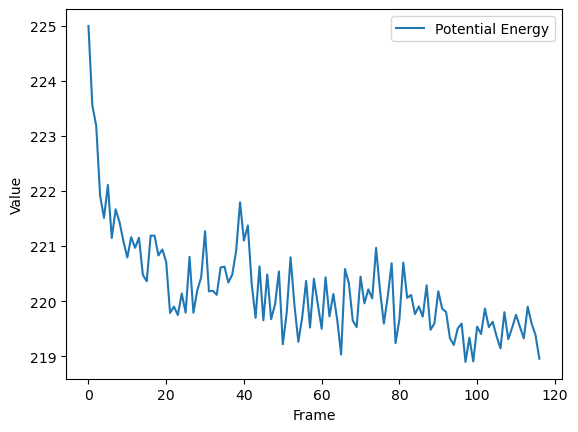

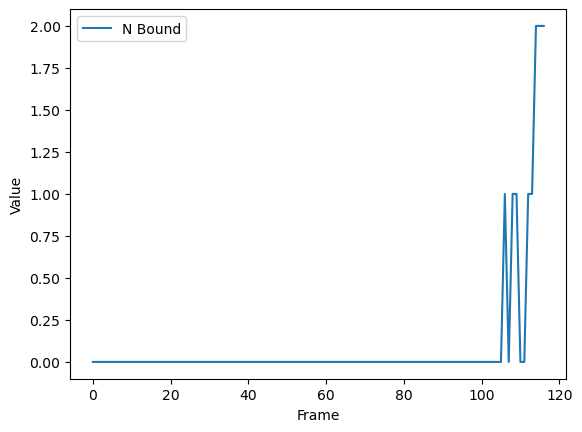

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


No assosciation

=== Running at kT = 0.5 ===


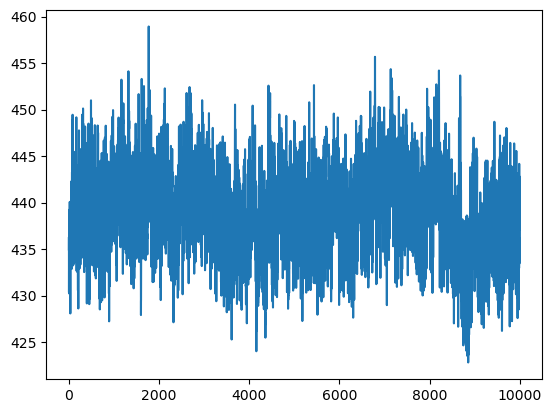

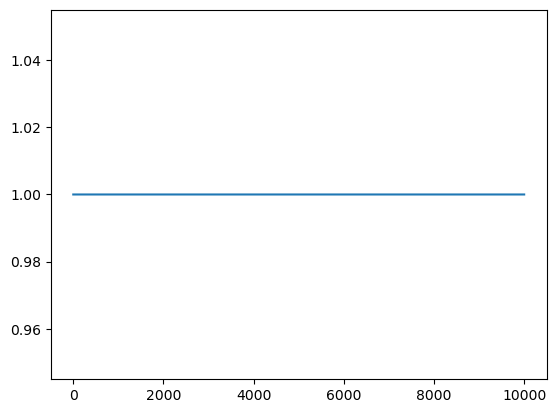

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=0.5: <n_bound>=2.00 / 2, <frac_bound>=1.00, <state>=0.000

=== Running at kT = 0.75 ===


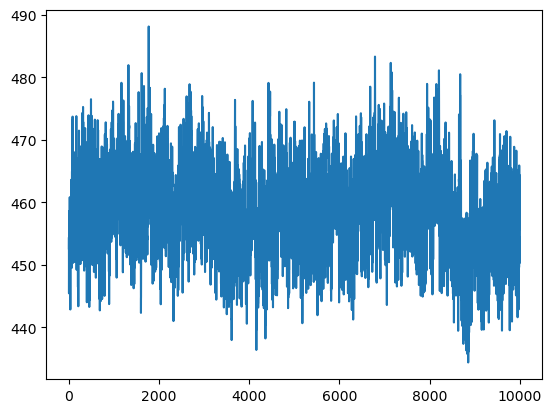

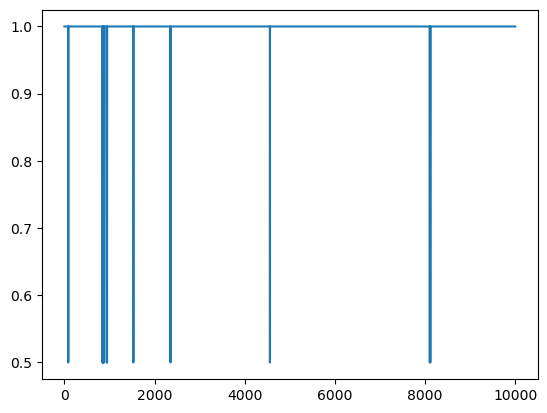

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=0.75: <n_bound>=2.00 / 2, <frac_bound>=1.00, <state>=0.000

=== Running at kT = 1.0 ===


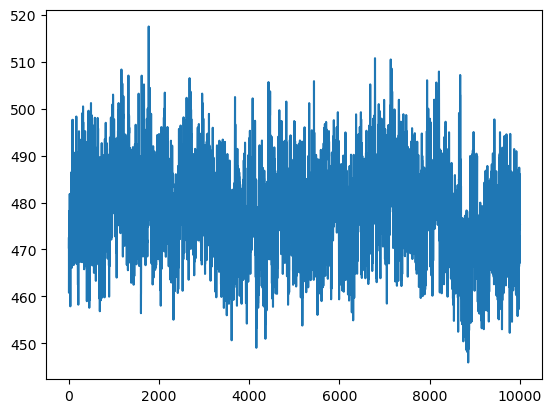

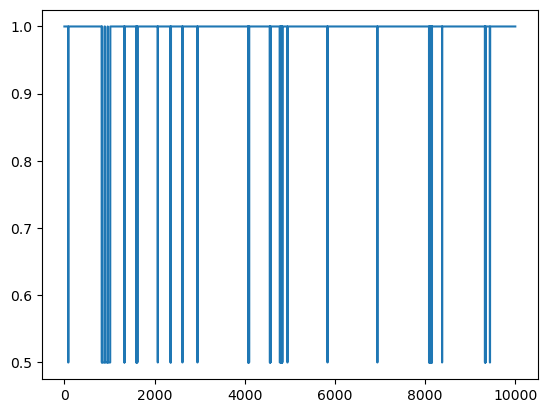

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=1.0: <n_bound>=1.97 / 2, <frac_bound>=0.98, <state>=0.000

=== Running at kT = 1.25 ===


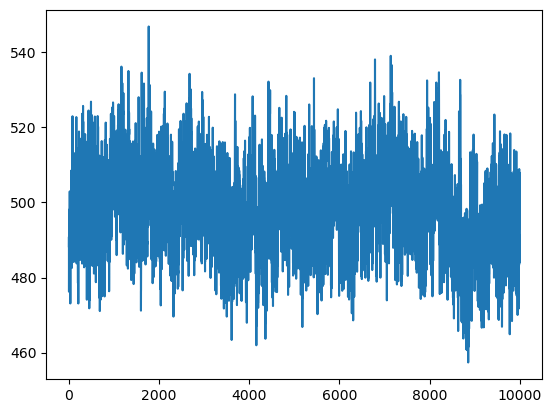

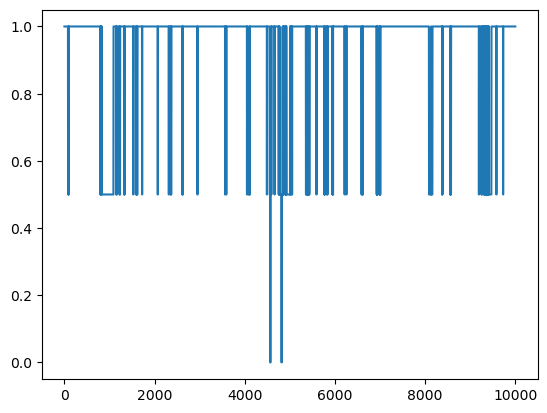

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=1.25: <n_bound>=1.91 / 2, <frac_bound>=0.95, <state>=0.001

=== Running at kT = 1.5 ===


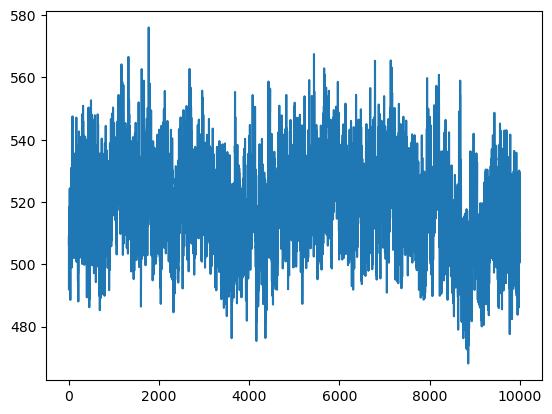

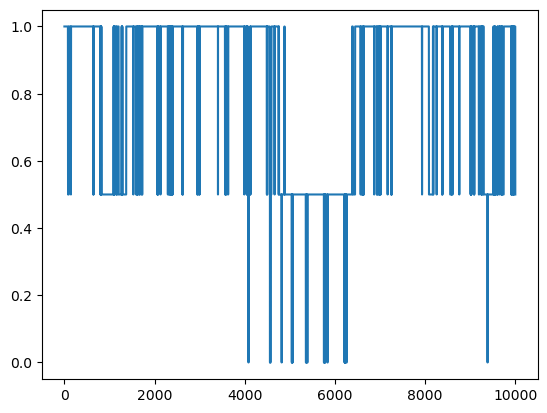

Failed to reach a solution to within tolerance with hybr: trying next method
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/utils.py:330: RuntimeWarning: divide by zero encountered in log
  out = np.log(numexpr.evaluate("exp(a - a_max)").sum(axis))
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:937: RuntimeWarning: invalid value encountered in add
  Log_W_nk[:, sa] += f_k[sa]  # normalize this row
Failed to reach a solution to within tolerance with hybr: trying next method
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/utils.py:330: RuntimeWarning: divide by zero 

kT=1.5: <n_bound>=1.68 / 2, <frac_bound>=0.84, <state>=0.011


/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]
*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


  T_k    = [0.5  0.75 1.   1.25 1.5 ]
  B_mean = [1.99997615 1.99584355 1.96839491 1.89127517 1.7039966 ]

Spacing = 4  (graft sites [9, 13])
No assosciation


*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


steps/sec: 6601.628958508322
No assosciation


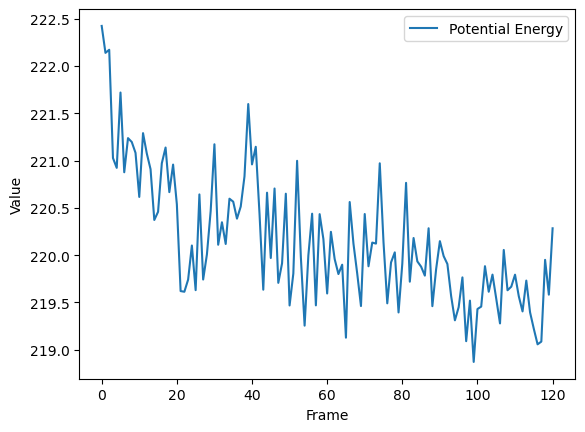

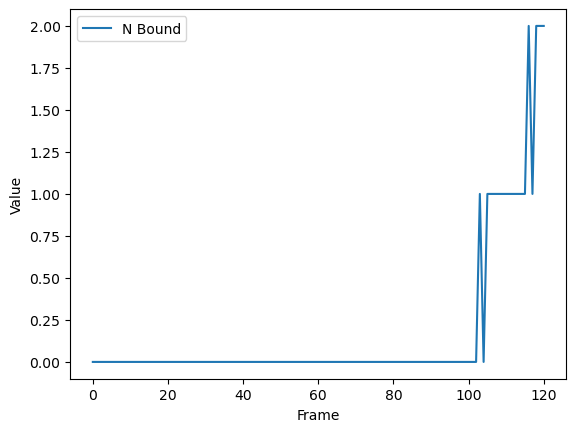

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


No assosciation

=== Running at kT = 0.5 ===


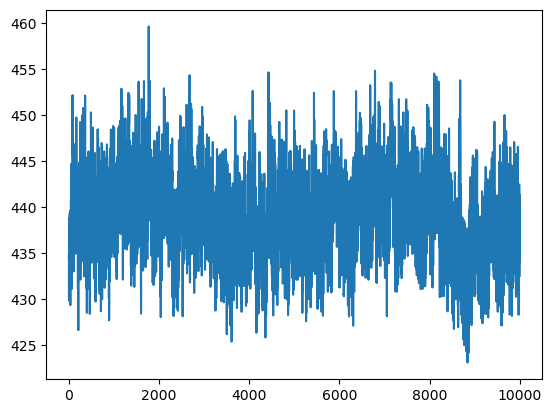

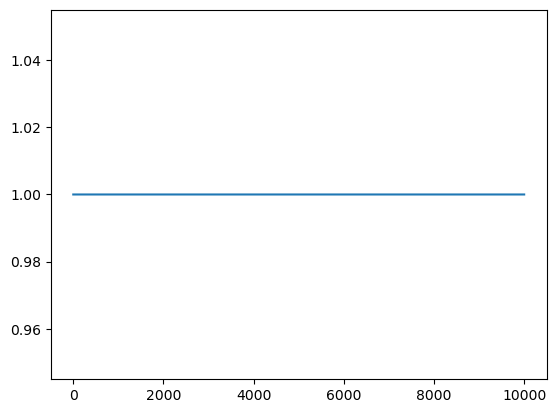

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=0.5: <n_bound>=2.00 / 2, <frac_bound>=1.00, <state>=0.000

=== Running at kT = 0.75 ===


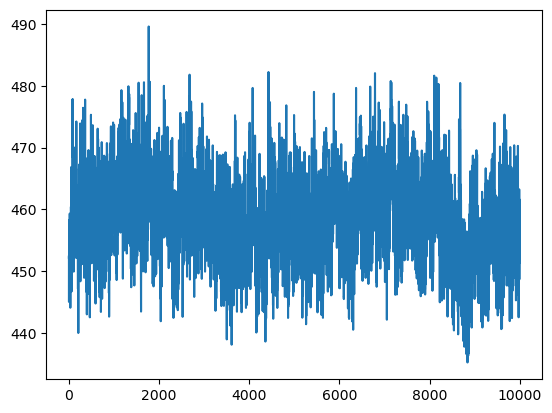

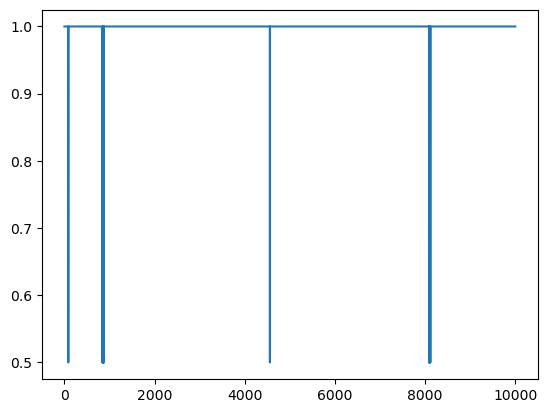

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=0.75: <n_bound>=2.00 / 2, <frac_bound>=1.00, <state>=0.000

=== Running at kT = 1.0 ===


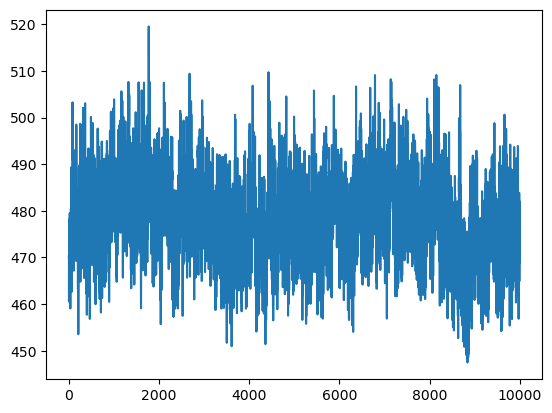

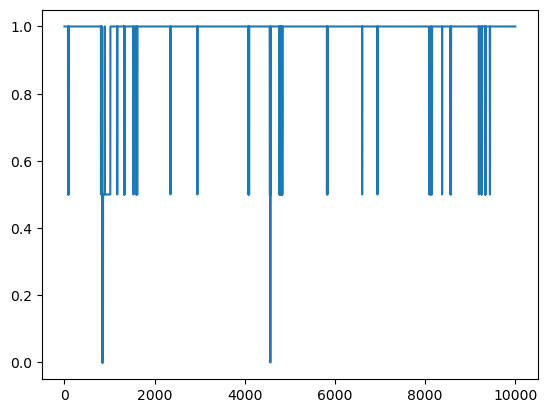

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=1.0: <n_bound>=1.96 / 2, <frac_bound>=0.98, <state>=0.001

=== Running at kT = 1.25 ===


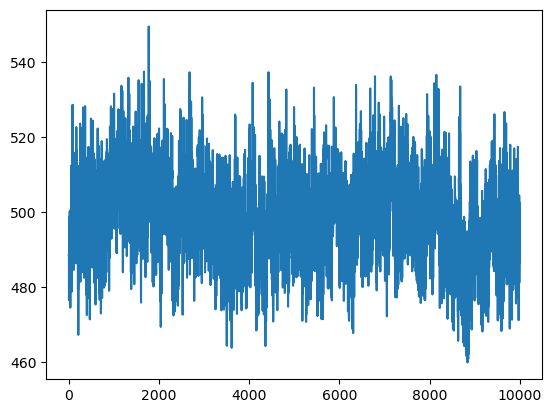

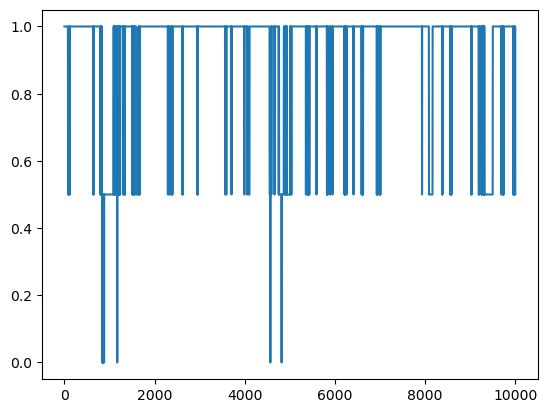

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=1.25: <n_bound>=1.87 / 2, <frac_bound>=0.93, <state>=0.004

=== Running at kT = 1.5 ===


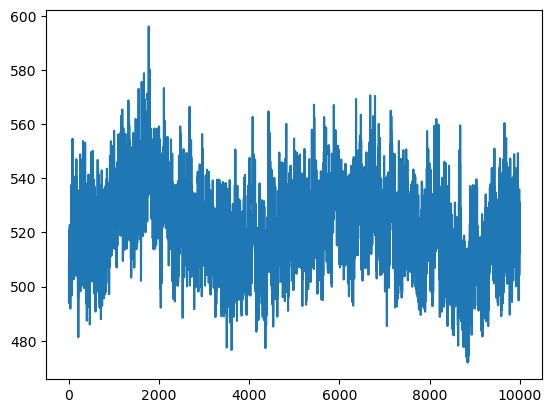

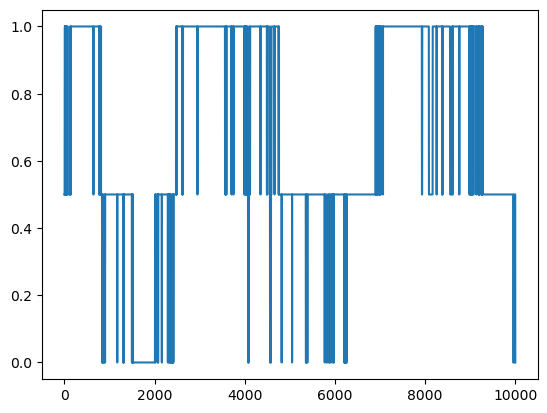

Failed to reach a solution to within tolerance with hybr: trying next method
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/utils.py:330: RuntimeWarning: divide by zero encountered in log
  out = np.log(numexpr.evaluate("exp(a - a_max)").sum(axis))
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:937: RuntimeWarning: invalid value encountered in add
  Log_W_nk[:, sa] += f_k[sa]  # normalize this row
Failed to reach a solution to within tolerance with hybr: trying next method
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]
Failed to reach a solution to within tolerance with hybr: trying next method
/Users/jaredhuzar/miniforge3/lib/

kT=1.5: <n_bound>=1.40 / 2, <frac_bound>=0.70, <state>=0.082


/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]
*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


  T_k    = [0.5  0.75 1.   1.25 1.5 ]
  B_mean = [1.99999253 1.99655292 1.95994944 1.84635436 1.45489402]

Spacing = 6  (graft sites [8, 14])
No assosciation


*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


steps/sec: 6741.211204890871
No assosciation


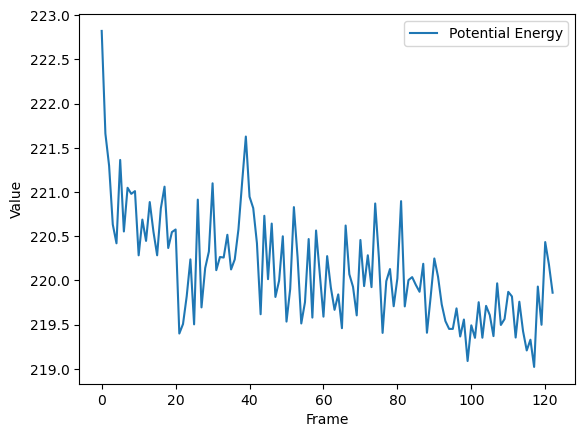

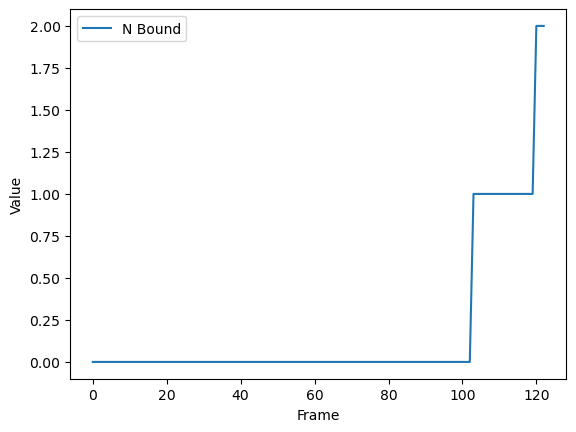

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


No assosciation

=== Running at kT = 0.5 ===


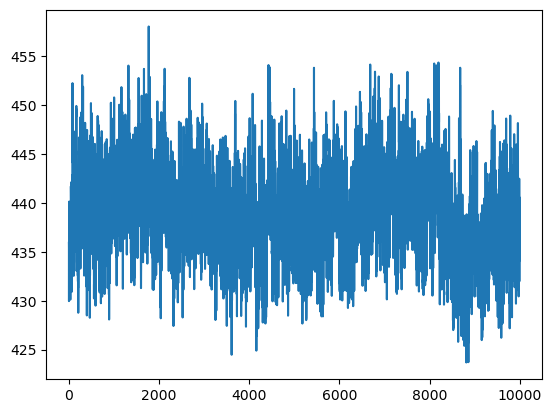

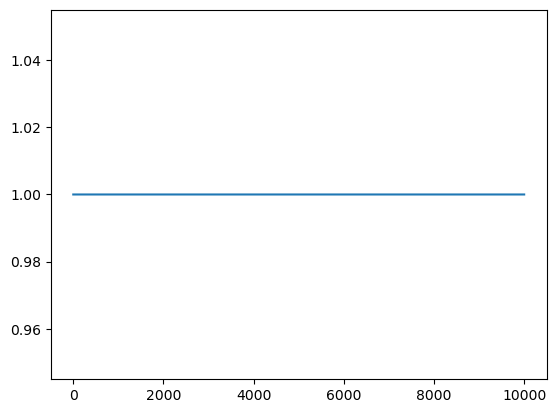

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=0.5: <n_bound>=2.00 / 2, <frac_bound>=1.00, <state>=0.000

=== Running at kT = 0.75 ===


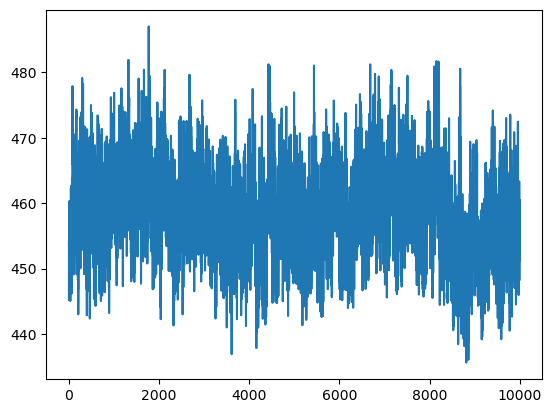

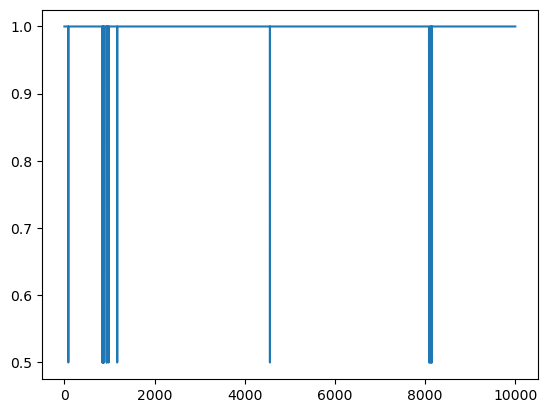

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=0.75: <n_bound>=1.99 / 2, <frac_bound>=1.00, <state>=0.000

=== Running at kT = 1.0 ===


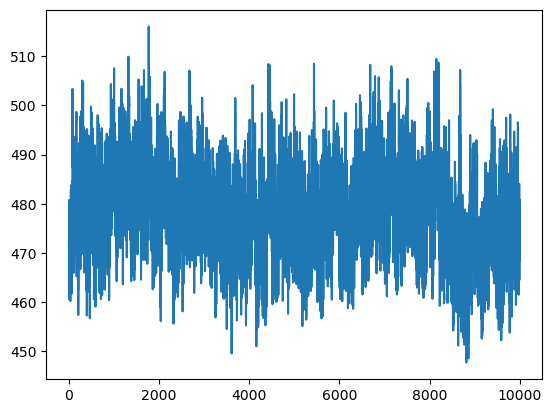

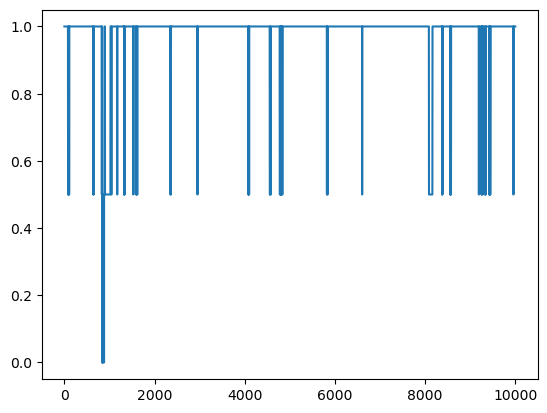

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=1.0: <n_bound>=1.96 / 2, <frac_bound>=0.98, <state>=0.001

=== Running at kT = 1.25 ===


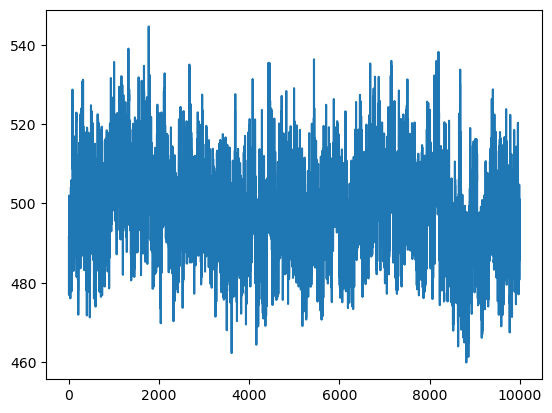

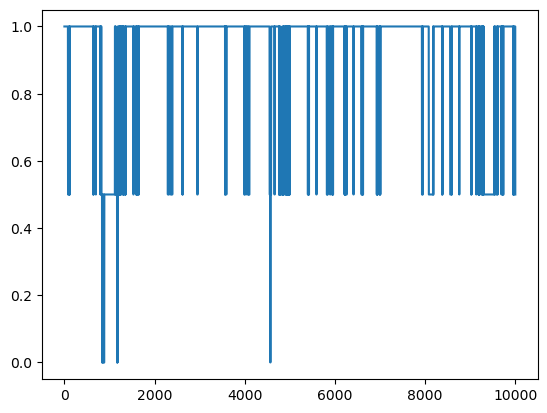

*Warning*: angle.harmonic: specified K <= 0
*Warning*: angle.harmonic: specified K <= 0


kT=1.25: <n_bound>=1.86 / 2, <frac_bound>=0.93, <state>=0.005

=== Running at kT = 1.5 ===


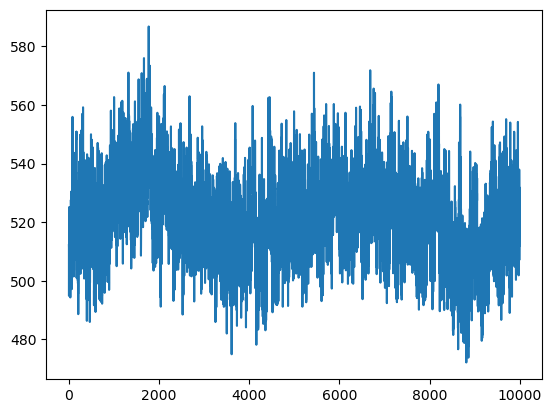

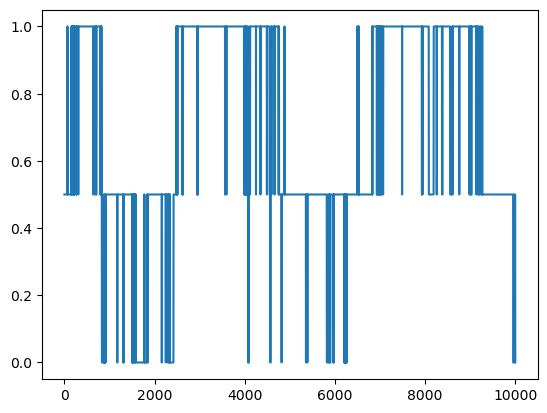

Failed to reach a solution to within tolerance with hybr: trying next method
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/utils.py:330: RuntimeWarning: divide by zero encountered in log
  out = np.log(numexpr.evaluate("exp(a - a_max)").sum(axis))
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:937: RuntimeWarning: invalid value encountered in add
  Log_W_nk[:, sa] += f_k[sa]  # normalize this row
Failed to reach a solution to within tolerance with hybr: trying next method
/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]
Failed to reach a solution to within tolerance with hybr: trying next method
/Users/jaredhuzar/miniforge3/lib/

kT=1.5: <n_bound>=1.42 / 2, <frac_bound>=0.71, <state>=0.062
  T_k    = [0.5  0.75 1.   1.25 1.5 ]
  B_mean = [1.99994333 1.99309396 1.95357548 1.83388747 1.47244284]


/Users/jaredhuzar/miniforge3/lib/python3.12/site-packages/pymbar/mbar.py:935: RuntimeWarning: divide by zero encountered in log
  Log_W_nk[:, sa] = np.log(A_n[i, ri]) + Log_W_nk[:, l]


In [20]:
# Sweep bridge spacings – all other parameters fixed.
# Graft sites are chosen symmetrically about rod centre (bead 11 of 22).
rod_center = 11
spacings = [2, 4, 6]           # gap (rod-bead units) between the 2 graft sites
bondGeometries_list = [
    [rod_center - s // 2, rod_center + s // 2] for s in spacings
]

numBonds             = 4               # 2 chains per rod -> 2 bridge bonds
beads_per_chain      = 3
bead_diameter        = 1
graft_spacing_ratio  = 1
tip_gap_ratio        = 6
d0_ratioInput        = 8              # Morse well depth in kT units
chain_bend_Stiffness = 10
rod_bend_Stiffness   = 80
rod_bond_Stiffness   = 60
chain_bond_stiffness = 50

# Temperature ladder spanning the expected melting range.
# Needs >=2 points for MBAR; each consecutive pair is an independent MBAR calculation.
Temperatures = sorted(set(list([0.5, 0.75, 1.0, 1.25, 1.5]) + [1.75, 2.0]))

resTotal = {}   # keyed by spacing value

for spacing, geom in zip(spacings, bondGeometries_list):
    print(f"\n{'='*60}\nSpacing = {spacing}  (graft sites {geom})\n{'='*60}")

    snapshot, bondsArr, anchor_tags, chain1_tags, signs = layoutSimulation(
        numBonds, beads_per_chain, bead_diameter,
        graft_spacing_ratio, tip_gap_ratio, geom, geom
    )

    sim = hoomd.Simulation(device=cpu, seed=42)
    sim.create_state_from_snapshot(snapshot)

    U_Morse, F_Morse, r_MorseMin, r_MorseMax = morse_Curve_Table(d0_ratio=d0_ratioInput)
    morseParams  = [U_Morse, F_Morse, r_MorseMin, r_MorseMax]
    chainParams  = [chain_bend_Stiffness, chain_bond_stiffness]
    rodParams    = [rod_bend_Stiffness, rod_bond_Stiffness]

    lj, angle_force, fene, rod_bond, bridge_bond, angle, dihedral, custom = forces_MD(
        morseParams, chainParams, rodParams,
        anchor_tags, chain1_tags, graft_spacing_ratio, signs
    )
    forces = [lj, angle_force, fene, rod_bond, bridge_bond, angle, dihedral, custom]
    simRelaxed = relax_MD(sim, forces)

    # Equilibrate with a very deep Morse well so both bridges always form first
    U_Morse1, F_Morse1, r_MorseMin1, r_MorseMax1 = morse_Curve_Table_assosciation(d0_ratio=100)
    morseParams1 = [U_Morse1, F_Morse1, r_MorseMin1, r_MorseMax1]
    lj, angle_force, fene, rod_bond, bridge_bond, angle, dihedral, custom = forces_MD(
        morseParams1, chainParams, rodParams,
        anchor_tags, chain1_tags, graft_spacing_ratio, signs
    )
    forces       = [lj, angle_force, fene, rod_bond, bridge_bond, angle, dihedral, custom]
    bridge_pairs = getBondPairs(bondsArr[0], bondsArr[1])
    simEquil     = Equilibrate_MD(simRelaxed, forces, bridge_pairs)
    snapshot_bound = simEquil.state.get_snapshot()

    # Temperature sweep with physical Morse parameters
    lj, angle_force, fene, rod_bond, bridge_bond, angle, dihedral, custom = forces_MD(
        morseParams, chainParams, rodParams,
        anchor_tags, chain1_tags, graft_spacing_ratio, signs
    )
    forces = [lj, angle_force, fene, rod_bond, bridge_bond, angle, dihedral, custom]
    raw_results, _ = standardized_melt(snapshot_bound, Temperatures, bridge_pairs, forces, RUN_TAG + "_sp%s" % spacing)

    # Collect arrays for pairwise MBAR (one list entry per temperature state)
    temps_list = [raw_results[a][2] for a in range(len(raw_results))]  # T(t)
    Us_list    = [raw_results[a][0] for a in range(len(raw_results))]  # U(t)
    Ns_list    = [raw_results[a][1] for a in range(len(raw_results))]  # n_bonds(t)

    mbar_out = pairwise_mbar_GHS_of_n(temps_list, Us_list, Ns_list, verbose=False)

    resTotal[spacing] = {'geom': geom, 'raw': raw_results, 'mbar': mbar_out}
    print(f"  T_k    = {mbar_out['T_k']}")
    print(f"  B_mean = {mbar_out['B_mean']}")


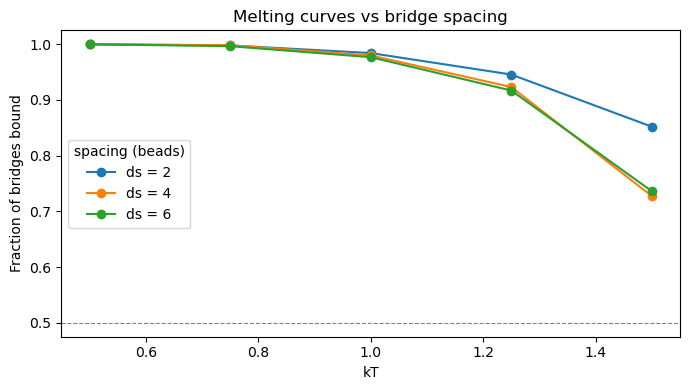

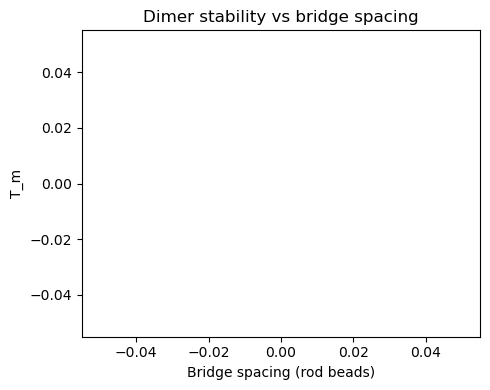

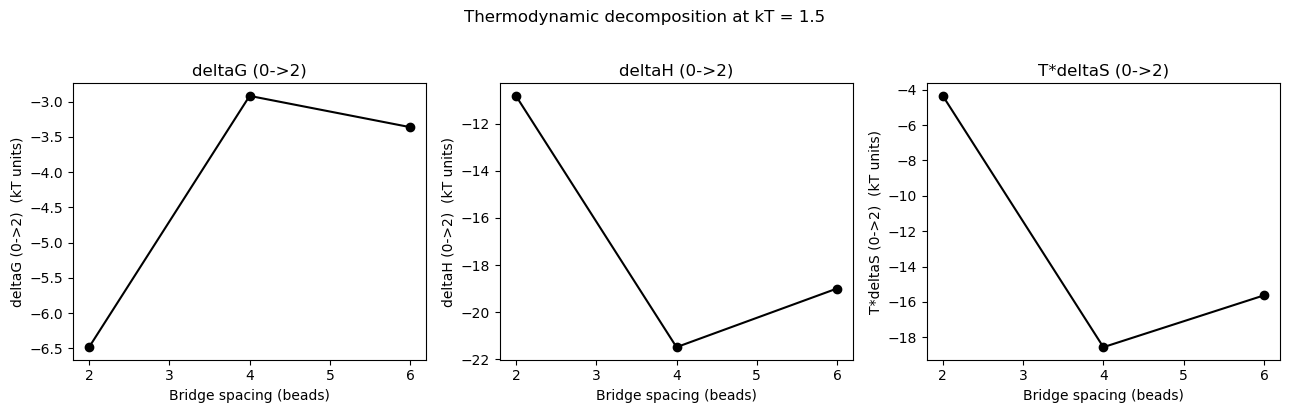

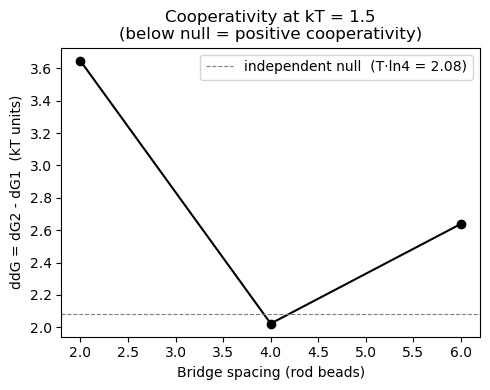

In [21]:
# ── Thermodynamic analysis: bridge-spacing effects ────────────────────────
spacing_list = sorted(resTotal.keys())
T_ref = 1.5   # reference temperature for single-point comparisons

summary = {}

for spacing in spacing_list:
    mbar   = resTotal[spacing]['mbar']
    T_k    = mbar['T_k']
    B_mean = mbar['B_mean']
    G_Tn   = mbar['G_Tn']   # (K, N_n): free energy of n-bond macrostate (min-shifted per T)
    H_Tn   = mbar['H_Tn']   # (K, N_n): conditional mean potential energy
    S_Tn   = mbar['S_Tn']   # (K, N_n): entropy (H-G)/T
    n_vals = mbar['n_vals']

    def n_idx(n):
        hits = np.where(n_vals == n)[0]
        return int(hits[0]) if len(hits) else None

    i0, i1, i2 = n_idx(0), n_idx(1), n_idx(2)

    # Melting temperature: interpolate where B_mean = 1.0 (half of max=2)
    T_m = np.nan
    valid = np.isfinite(B_mean)
    if valid.sum() >= 2:
        Tv, Bv = T_k[valid], B_mean[valid]
        if Bv[0] > 1.0 and Bv[-1] < 1.0:
            T_m = float(np.interp(1.0, Bv[::-1], Tv[::-1]))

    K = len(T_k)
    dG_total = np.full(K, np.nan)   # G(n=2) - G(n=0): overall dimerisation stability
    dH_total = np.full(K, np.nan)
    dS_total = np.full(K, np.nan)   # entropy units; multiply by T for TdeltaS
    dG1      = np.full(K, np.nan)   # G(1) - G(0): free energy cost of first bridge
    dG2      = np.full(K, np.nan)   # G(2) - G(1): free energy cost of second bridge
    ddG      = np.full(K, np.nan)   # cooperativity = dG2 - dG1

    ds1      = np.full(K, np.nan)   # G(1) - G(0): free energy cost of first bridge
    ds2      = np.full(K, np.nan)   # G(2) - G(1): free energy cost of second bridge
    ddS      = np.full(K, np.nan)   # cooperativity = dG2 - dG1

    dh1      = np.full(K, np.nan)   # G(1) - G(0): free energy cost of first bridge
    dh2      = np.full(K, np.nan)   # G(2) - G(1): free energy cost of second bridge
    ddH      = np.full(K, np.nan)   # cooperativity = dG2 - dG1

    for k in range(K):
        g0 = G_Tn[k, i0] if i0 is not None else np.nan
        g1 = G_Tn[k, i1] if i1 is not None else np.nan
        g2 = G_Tn[k, i2] if i2 is not None else np.nan
        h0 = H_Tn[k, i0] if i0 is not None else np.nan
        h1 = H_Tn[k, i1] if i1 is not None else np.nan
        h2 = H_Tn[k, i2] if i2 is not None else np.nan
        s0 = S_Tn[k, i0] if i0 is not None else np.nan
        s1 = S_Tn[k, i1] if i1 is not None else np.nan
        s2 = S_Tn[k, i2] if i2 is not None else np.nan

        if np.isfinite(g0) and np.isfinite(g2):
            dG_total[k] = g2 - g0
            dH_total[k] = h2 - h0
            dS_total[k] = s2 - s0
        if np.isfinite(g0) and np.isfinite(g1):
            dG1[k] = g1 - g0
        if np.isfinite(g1) and np.isfinite(g2):
            dG2[k] = g2 - g1
        if np.isfinite(dG1[k]) and np.isfinite(dG2[k]):
            ddG[k] = dG2[k] - dG1[k]

        if np.isfinite(h0) and np.isfinite(h1):
            dh1[k] = h1 - h0
        if np.isfinite(h1) and np.isfinite(h2):
            dh2[k] = h2 - h1
        if np.isfinite(dh1[k]) and np.isfinite(dh2[k]):
            ddH[k] = dh2[k] - dh1[k]

        if np.isfinite(s0) and np.isfinite(s1):
            ds1[k] = s1 - s0
        if np.isfinite(h1) and np.isfinite(h2):
            ds2[k] = s2 - s1
        if np.isfinite(ds1[k]) and np.isfinite(ds2[k]):
            ddS[k] = ds2[k] - ds1[k]

    def at_Tref(arr):
        fin = np.isfinite(arr)
        return float(np.interp(T_ref, T_k[fin], arr[fin])) if fin.sum() >= 2 else np.nan

    summary[spacing] = dict(
        T_k=T_k, B_mean=B_mean, T_m=T_m,
        dG_total=dG_total, dH_total=dH_total, dS_total=dS_total,
        dG1=dG1, dG2=dG2, ddG=ddG,
        dh1=dh1,dh2=dh2,ddH=ddH,
        ds1=ds1,ds2=ds2,ddS=ddS,
        dG_ref =at_Tref(dG_total),
        dH_ref =at_Tref(dH_total),
        TdS_ref=at_Tref(dH_total) - at_Tref(dG_total),  # enforce dG=dH-TdS; never multiply interpolated dS by a different T
        ddG_ref=at_Tref(ddG),
        #ddS_ref = at_Tref(ddS),
        #ddH_ref = at_Tref(ddH),
    )

# ── Figure 1: melting curves ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
for sp in spacing_list:
    s = summary[sp]
    ax.plot(s['T_k'], s['B_mean'] / 2, 'o-', label=f'ds = {sp}')
ax.axhline(0.5, ls='--', color='gray', lw=0.8)
ax.set_xlabel('kT')
ax.set_ylabel('Fraction of bridges bound')
ax.set_title('Melting curves vs bridge spacing')
ax.legend(title='spacing (beads)')
plt.tight_layout(); plt.show()

# ── Figure 2: melting temperature (stability) ─────────────────────────────
T_ms = [summary[sp]['T_m'] for sp in spacing_list]
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(spacing_list, T_ms, 'ko-')
ax.set_xlabel('Bridge spacing (rod beads)')
ax.set_ylabel('T_m')
ax.set_title('Dimer stability vs bridge spacing')
plt.tight_layout(); plt.show()

# ── Figure 3: deltaG, deltaH, T*deltaS (0->2 transition) at T_ref ──────────
labels = ['deltaG (0->2)', 'deltaH (0->2)', 'T*deltaS (0->2)']
keys   = ['dG_ref',        'dH_ref',        'TdS_ref']
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, lbl, key in zip(axes, labels, keys):
    vals = [summary[sp][key] for sp in spacing_list]
    ax.plot(spacing_list, vals, 'ko-')
    ax.set_xlabel('Bridge spacing (beads)')
    ax.set_ylabel(f'{lbl}  (kT units)')
    ax.set_title(lbl)
plt.suptitle(f'Thermodynamic decomposition at kT = {T_ref}', y=1.02)
plt.tight_layout(); plt.show()

# ── Figure 4: cooperativity ddG = dG2 - dG1 ──────────────────────────────
# Independent binding null: ddG = T_ref * ln(4) ≈ 1.386 * T_ref
#   because n=1 has 2 degenerate microstates, shifting G(1) down by T*ln(2)
# ddG < T_ref*ln(4): positively cooperative (n=1 more depleted than expected)
# ddG > T_ref*ln(4): anti-cooperative (n=1 enriched relative to independent)
ddG_vals = [summary[sp]['ddG_ref'] for sp in spacing_list]
independent_null = T_ref * np.log(4)
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(spacing_list, ddG_vals, 'ko-')
ax.axhline(independent_null, ls='--', color='gray', lw=0.8,
           label=f'independent null  (T·ln4 = {independent_null:.2f})')
ax.set_xlabel('Bridge spacing (rod beads)')
ax.set_ylabel('ddG = dG2 - dG1  (kT units)')
ax.set_title(f'Cooperativity at kT = {T_ref}\n'
             '(below null = positive cooperativity)')
ax.legend()
plt.tight_layout(); plt.show()


In [22]:
print(f"Summary at kT = {T_ref}:")
print(f"{'Spacing':>8}  {'T_m':>8}  {'dG(0->2)':>10}  "
      f"{'dH(0->2)':>10}  {'T*dS(0->2)':>12}  {'ddG':>10}")
for sp in spacing_list:
    s = summary[sp]
    pd.DataFrame(s).to_csv(f"SummaryRigid_Low_{sp}.csv")
    print(f"{sp:>8}  {s['T_m']:>8.3f}  {s['dG_ref']:>10.3f}  "
          f"{s['dH_ref']:>10.3f}  {s['TdS_ref']:>12.3f}  {s['ddG_ref']:>10.3f}")

Summary at kT = 1.5:
 Spacing       T_m    dG(0->2)    dH(0->2)    T*dS(0->2)         ddG
       2       nan      -6.483     -10.830        -4.346       3.646
       4       nan      -2.919     -21.479       -18.559       2.023
       6       nan      -3.363     -18.993       -15.630       2.639


In [23]:
f"SummaryRigid_Low_{sp}.csv"

'SummaryRigid_Low_6.csv'

In [24]:
pd.DataFrame(s).to_csv('SummaryRigid_Low.csv')